<a href="https://colab.research.google.com/github/kandargvgf/RecAI/blob/main/site/en/tutorials/customization/custom_layers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Detecting spam emails using tensorflow in python

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import string
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
nltk.download('stopwords')

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

import warnings
warnings.filterwarnings('ignore')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [80]:
!pip install opendatasets

In [81]:
import opendatasets as od
od.download("https://www.kaggle.com/datasets/ashfakyeafi/spam-email-classification")

Skipping, found downloaded files in "./spam-email-classification" (use force=True to force download)


In [82]:
import pandas as pd

In [83]:
data = pd.read_csv('spam-email-classification/email.csv')
data.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [84]:
import os
print(os.listdir('spam-email-classification'))

['email.csv']


In [85]:
data.shape

(5573, 2)

In [86]:
print(list(data.columns))


['Category', 'Message']


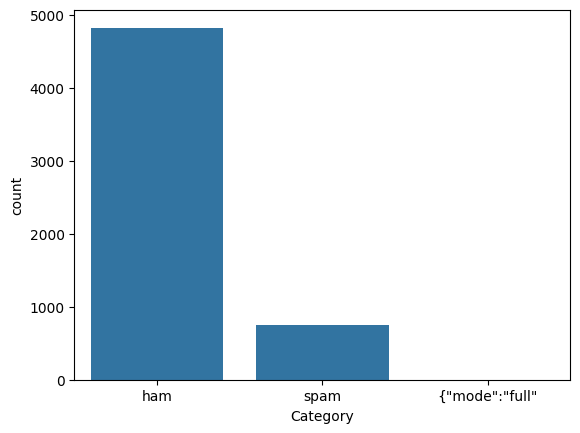

In [87]:
sns.countplot(x='Category',data=data)
plt.show()

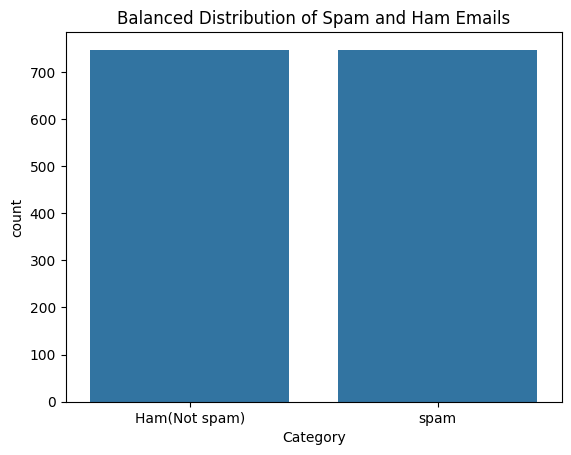

In [88]:
ham_msg = data[data['Category'] == 'ham']
spam_msg = data[data['Category'] == 'spam']

#downsample ham emails to match the number of spam emails

ham_msg_balanced = ham_msg.sample(n=len(spam_msg),random_state=42)

#combine balanced data
balanced_data = pd.concat([ham_msg_balanced,spam_msg]).reset_index(drop=True)

#visualize the balanced dataset

sns.countplot(x='Category', data=balanced_data)
plt.title("Balanced Distribution of Spam and Ham Emails")
plt.xticks(ticks=[0,1], labels=['Ham(Not spam)', 'spam'])
plt.show()

In [89]:
balanced_data['Message'] = balanced_data['Message'].str.replace('Subject', '')
balanced_data.head()

,Category,Message
0,ham,If i not meeting ü all rite then i'll go home ...
1,ham,"I.ll always be there, even if its just in spir..."
2,ham,"Sorry that took so long, omw now"
3,ham,I thk 50 shd be ok he said plus minus 10.. Did...
4,ham,Dunno i juz askin cos i got a card got 20% off...


In [90]:
punctuations_list = string.punctuation
def remove_punctuations(text):
    temp = str.maketrans('', '', punctuations_list)
    return text.translate(temp)

balanced_data['Message']= balanced_data['Message'].apply(lambda x: remove_punctuations(x))
balanced_data.head()

,Category,Message
0,ham,If i not meeting ü all rite then ill go home l...
1,ham,Ill always be there even if its just in spirit...
2,ham,Sorry that took so long omw now
3,ham,I thk 50 shd be ok he said plus minus 10 Did ü...
4,ham,Dunno i juz askin cos i got a card got 20 off ...


In [91]:
def remove_stopwords(text):
  stop_words = stopwords.words('english')

  imp_words = []
  for word in str(text).split():
    word = word.lower()

    if word not in stop_words:
      imp_words.append(word)

  output = " ".join(imp_words)
  return output

balanced_data['text'] = balanced_data['Message'].apply(lambda text:
                                                          remove_stopwords(text))
balanced_data.head()

,Category,Message,text
0,ham,If i not meeting ü all rite then ill go home l...,meeting ü rite ill go home lor ü dun feel like...
1,ham,Ill always be there even if its just in spirit...,ill always even spirit ill get bb soon trying ...
2,ham,Sorry that took so long omw now,sorry took long omw
3,ham,I thk 50 shd be ok he said plus minus 10 Did ü...,thk 50 shd ok said plus minus 10 ü leave line ...
4,ham,Dunno i juz askin cos i got a card got 20 off ...,dunno juz askin cos got card got 20 4 salon ca...


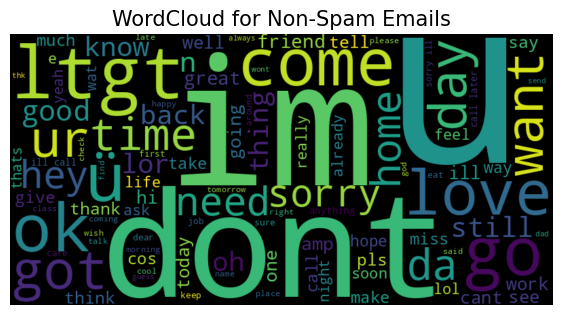

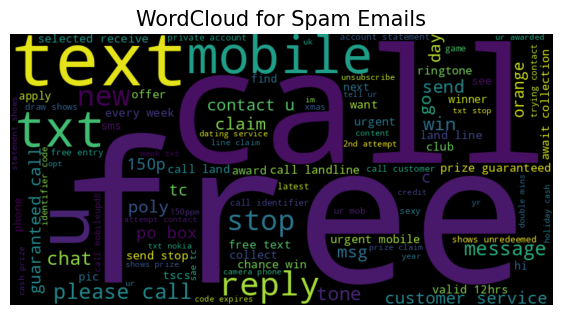

In [92]:
def plot_word_cloud(data, typ):
    email_corpus = " ".join(data['text'])
    wc = WordCloud(background_color='black', max_words=100, width=800, height=400).generate(email_corpus)
    plt.figure(figsize=(7, 7))
    plt.imshow(wc, interpolation='bilinear')
    plt.title(f'WordCloud for {typ} Emails', fontsize=15)
    plt.axis('off')
    plt.show()

plot_word_cloud(balanced_data[balanced_data['Category'] == 'ham'], typ='Non-Spam')
plot_word_cloud(balanced_data[balanced_data['Category'] == 'spam'], typ='Spam')

In [93]:
train_x, test_x, train_Y, tst_Y = train_test_split(
    balanced_data['text'], balanced_data['Category'], test_size=0.2, random_state=42
)
tokenizer = Tokenizer()
tokenizer.fit_on_texts(train_x)

train_sequences = tokenizer.texts_to_sequences(train_x)
test_sequences = tokenizer.texts_to_sequences(test_x)

max_len = 100
train_sequences = pad_sequences(train_sequences, maxlen=max_len,
                                padding='post', truncating='post')
test_sequences = pad_sequences(test_sequences, maxlen=max_len, padding='post', truncating='post')

train_Y = (train_Y == 'spam').astype(int)
tst_Y = (tst_Y == 'spam').astype(int)

In [94]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Embedding(input_dim=len(tokenizer.word_index) + 1, output_dim=32, input_length=max_len),
    tf.keras.layers.LSTM(16),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')  # Output layer
])

model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False), # Changed from_logits to False
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [95]:
es = EarlyStopping(patience=3,monitor='val_accuracy',restore_best_weights=True)
lr = ReduceLROnPlateau(patience=2,monitor='val_loss',factor=0.5, verbose=0)

history = model.fit(
    train_sequences,train_Y,
    validation_data=(test_sequences, tst_Y),epochs=20,
    batch_size=12,
    callbacks=[lr, es]
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 16s 111ms/step - accuracy: 0.4651 - loss: 0.6940 - val_accuracy: 0.4849 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.5021 - loss: 0.6933 - val_accuracy: 0.4849 - val_loss: 0.6935 - learning_rate: 0.0010
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.4921 - loss: 0.6935 - val_accuracy: 0.4849 - val_loss: 0.6934 - learning_rate: 0.0010
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.4771 - loss: 0.6935 - val_accuracy: 0.4849 - val_loss: 0.6934 - learning_rate: 5.0000e-04


In [96]:
test_loss, test_accuracy = model.evaluate(test_sequences, tst_Y)
print('Test Loss :',test_loss)
print('Test Accuracy :',test_accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5028 - loss: 0.6931
Test Loss : 0.6932392716407776
Test Accuracy : 0.48494982719421387


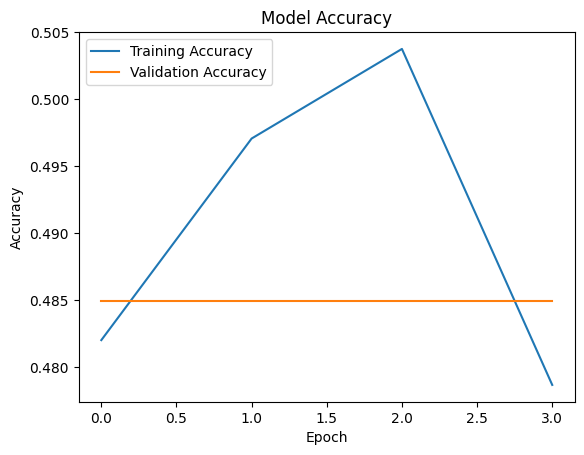

In [97]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()